In [9]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import scipy.stats as stats
import sympy as sym
import matplotlib.pyplot as plt
import cvxpy as cv

Part A

In [10]:
fred = pd.read_csv("FEDMINNFRWG.csv")

N = len(fred)
t = np.arange(1, N+1)
lmbda = [1,10,100,1000]

fred.head()

,observation_date,FEDMINNFRWG
0,1938-10-01,0.25
1,1938-11-01,0.25
2,1938-12-01,0.25
3,1939-01-01,0.25
4,1939-02-01,0.25


In [11]:
X = np.zeros((N,N))
for i in range(1,N):
    X[:,i] = t>i
X[:,0] = 1
sym.pprint(X)

[[1. 0. 0. ... 0. 0. 0.] 
 [1. 1. 0. ... 0. 0. 0.] 
 [1. 1. 1. ... 0. 0. 0.] 
           ...           
 [1. 1. 1. ... 1. 0. 0.] 
 [1. 1. 1. ... 1. 1. 0.] 
 [1. 1. 1. ... 1. 1. 1.]]


In [12]:
y = np.array(fred['FEDMINNFRWG'])
b = X.T @ y
D = np.ones((N))
D[0] = 0
D = np.diag(D)
sym.pprint(D)
ridge_fits = {}
for lam in lmbda:
    A = X.T @ X + lam*D
    beta_hat = np.linalg.solve(A,b)
    mu_hat = X @ beta_hat
    ridge_fits[lam] = mu_hat


[[0. 0. 0. ... 0. 0. 0.] 
 [0. 1. 0. ... 0. 0. 0.] 
 [0. 0. 1. ... 0. 0. 0.] 
           ...           
 [0. 0. 0. ... 1. 0. 0.] 
 [0. 0. 0. ... 0. 1. 0.] 
 [0. 0. 0. ... 0. 0. 1.]]


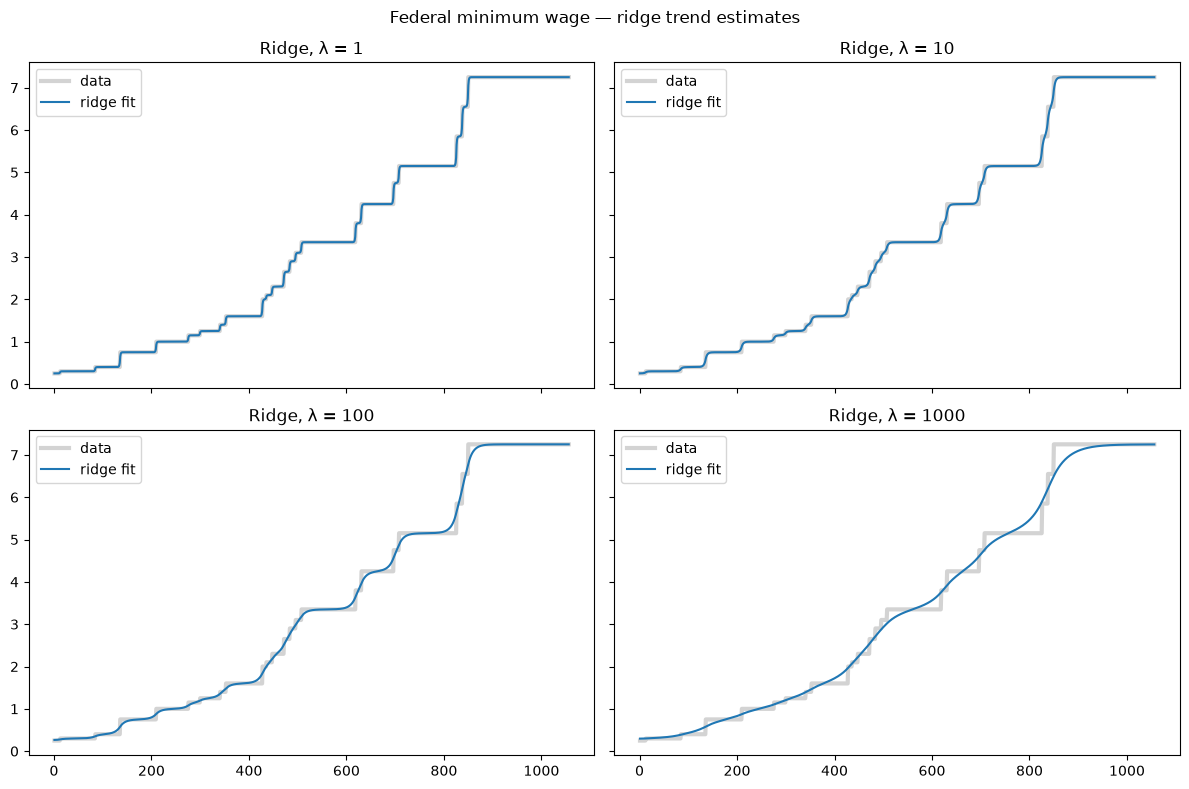

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, (lam, mu_hat) in zip(axes.flat, ridge_fits.items()):
    ax.plot(t, y, color='lightgray', lw=3, label='data')
    ax.plot(t, mu_hat, color='C0', lw=1.5, label='ridge fit')
    ax.set_title(f'Ridge, λ = {lam}')
    ax.legend(loc='upper left')
fig.suptitle('Federal minimum wage — ridge trend estimates')
fig.tight_layout(); plt.show()

Lambda = 1 looks ot model the best. While all the ridge fits seem to graph the overall trend lambda =1 is able to capture the piecewise steps better than any of the other grpahs

Part B

In [14]:
lasso_fits = {}
lasso_betas = {}
for lam in lmbda:
    beta = cv.Variable(N)
    obj = cv.Minimize(cv.sum_squares(y-X@beta) + lam*cv.norm1(beta[1:]))
    cv.Problem(obj).solve()
    mu_hat = X@beta.value
    lasso_fits[lam] = mu_hat
    lasso_betas[lam] = beta.value.copy()



C:\Users\matth\AppData\Local\Temp\ipykernel_22184\948448631.py:6: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  cv.Problem(obj).solve()


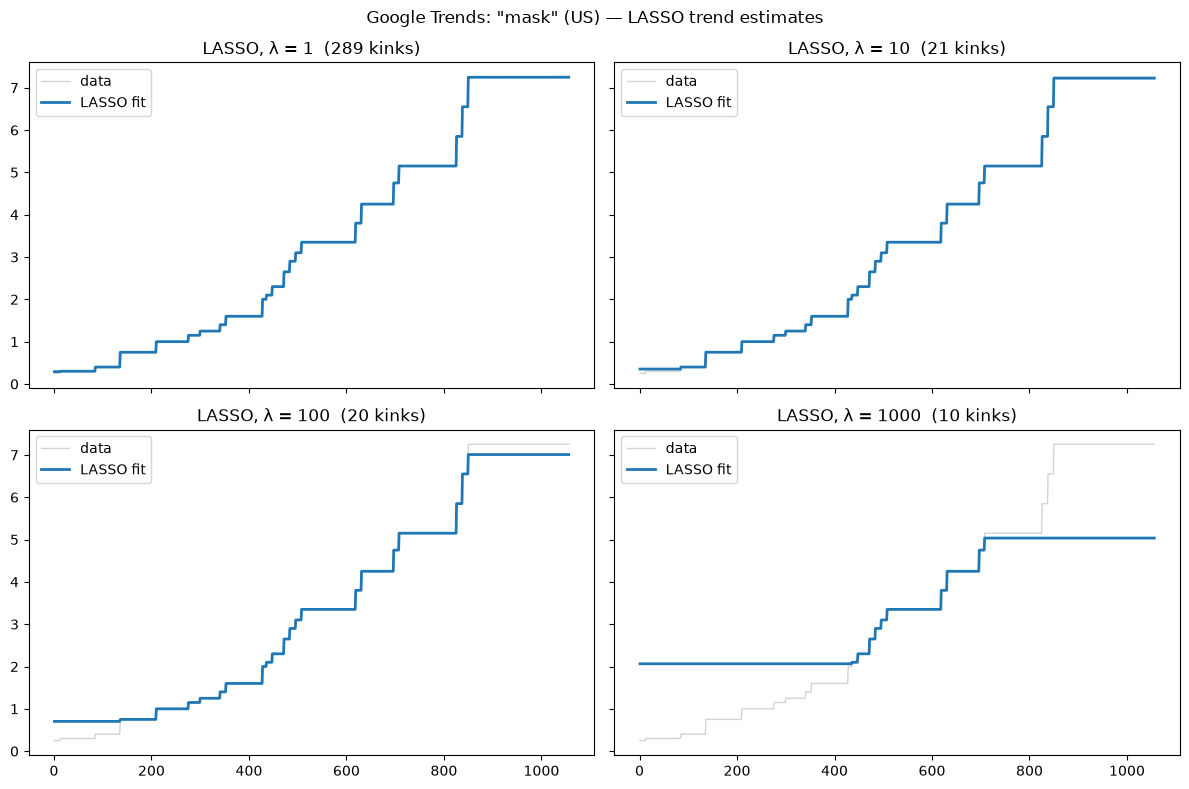

In [15]:
def plot_fits(fits, y, dates, method, betas=None):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
    for ax, (lam, mu_hat) in zip(axes.flat, fits.items()):
        ax.plot(dates, y, color='lightgray', lw=1, label='data')
        ax.plot(dates, mu_hat, color='C0', lw=2, label=f'{method} fit')
        title = f'{method}, λ = {lam}'
        if betas is not None:
            kinks = np.sum(np.abs(betas[lam][1:]) > 1e-6)
            title += f'  ({kinks} kinks)'
        ax.set_title(title)
        ax.legend(loc='upper left')
    fig.suptitle(f'Google Trends: "mask" (US) — {method} trend estimates')
    fig.tight_layout()
    plt.show()

plot_fits(lasso_fits, y, t, 'LASSO', betas=lasso_betas)

We see here that lambda 1 and lambda 10 look identical will a seemingly perfect fit capturing all the piecewise jumps. I would ultimately choose lasso with lambda = 10 because lambda with 289 kinks may be overfitting and we can sense this because there is not visible or noticable difference between the 2 models. 

Part C

I would choose lasso with lambda = 10 because we see with lasso that it is far better at capturing the piecewise jumps and similar lambda = 10 seems to not be overfitting the data nearly as much as lambda =1. We can also compare ridge and lasso and see how well the capturing of these jumps differ hence why I would choose a lasso regression model.